In [1]:
import pandas as pd

In [2]:
df=pd.read_csv('anime_dataset_1.csv')

In [3]:
df.sample(25)

,anime_id,anime_title,genres,type,episodes,rating,year_of_release
895,896,To LOVE Ru Darkness 2,Comedy|Ecchi|Harem|Romance|School|Sci-Fi|Shounen,TV,12,7.68,2015
23,24,Ace of Diamond,Comedy|School|Shounen|Sports,TV,75,8.19,2013
67,68,Astarotte's Toy,Comedy|Demons|Ecchi|Fantasy|Romance|Seinen,TV,12,6.73,2011
226,227,Dusk Maiden of Amnesia,Horror|Mystery|Romance|School|Shounen|Supernat...,TV,12,7.93,2012
239,240,Excel Saga,Comedy|Parody|Sci-Fi|Shounen,TV,26,7.55,1999
766,767,Shakugan no Shana: Season III,Action|Drama|Fantasy|Romance|Supernatural,TV,24,7.65,2011
594,595,Naruto: Shippuden,Action|Adventure|Comedy|Martial Arts|Shounen|S...,TV,500,8.19,2007
101,102,Blade Dance of the Elementalers,Action|Comedy|Ecchi|Fantasy|Harem|Romance|Scho...,TV,12,7.06,2014
514,515,Luck & Logic,Action|Fantasy,TV,12,6.21,2016
628,629,Nyaruko: Crawling With Love! Second Season,Comedy|Parody|Sci-Fi,TV,12,7.38,2013


In [4]:
df.shape

(1000, 7)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   anime_id         1000 non-null   int64  
 1   anime_title      1000 non-null   str    
 2   genres           1000 non-null   str    
 3   type             1000 non-null   str    
 4   episodes         1000 non-null   int64  
 5   rating           1000 non-null   float64
 6   year_of_release  1000 non-null   int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 111.7 KB


In [6]:
df.describe()

,anime_id,episodes,rating,year_of_release
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,22.416000,7.601330,2011.469000
std,288.819436,33.061246,0.645872,5.381264
min,1.000000,4.000000,3.670000,1979.000000
25%,250.750000,12.000000,7.240000,2008.000000
50%,500.500000,13.000000,7.610000,2013.000000
75%,750.250000,24.000000,8.050000,2015.000000
max,1000.000000,500.000000,9.240000,2022.000000


In [7]:
df.isnull().sum

<bound method DataFrame.sum of      anime_id  anime_title  genres   type  episodes  rating  year_of_release
0       False        False   False  False     False   False            False
1       False        False   False  False     False   False            False
2       False        False   False  False     False   False            False
3       False        False   False  False     False   False            False
4       False        False   False  False     False   False            False
..        ...          ...     ...    ...       ...     ...              ...
995     False        False   False  False     False   False            False
996     False        False   False  False     False   False            False
997     False        False   False  False     False   False            False
998     False        False   False  False     False   False            False
999     False        False   False  False     False   False            False

[1000 rows x 7 columns]>

In [8]:
df.duplicated().sum()

np.int64(0)

# Univariate Analysis

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

## Anime Rating

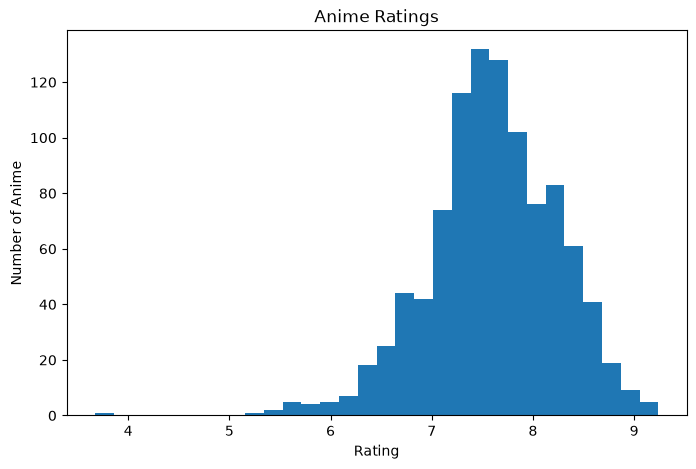

In [10]:
plt.figure(figsize=(8,5))

plt.hist(df['rating'], bins=30)

plt.xlabel("Rating")
plt.ylabel("Number of Anime")
plt.title("Anime Ratings")

plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_8152\1278236239.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['rating'], vert=False)


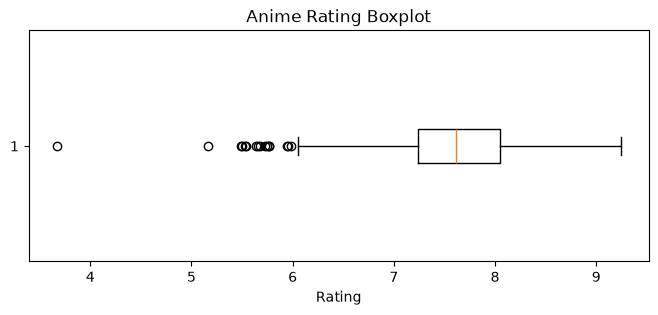

In [11]:
plt.figure(figsize=(8,3))

plt.boxplot(df['rating'], vert=False)

plt.xlabel("Rating")
plt.title("Anime Rating Boxplot")

plt.show()

#### By ploting the rating graph in the form of histogram and boxplot we can clearly see that rating of most of the anime is in the range of 7 to 8.3 and in boxplot we can figure out there are many outliers (Left side) this means there are also some animes whose rating is even less than 6.

In [12]:
rate_info = df[['rating']]   



In [13]:
rate_info.describe()

,rating
count,1000.000000
mean,7.601330
std,0.645872
min,3.670000
25%,7.240000
50%,7.610000
75%,8.050000
max,9.240000


## Episode distribution

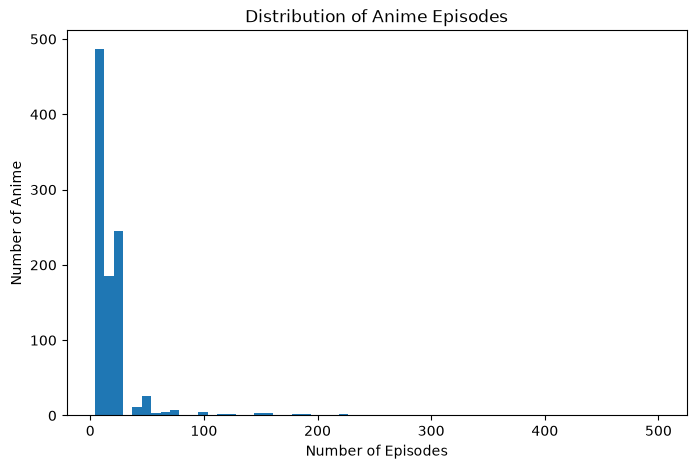

In [14]:
plt.figure(figsize=(8,5))

plt.hist(df['episodes'], bins=60)

plt.xlabel("Number of Episodes")
plt.ylabel("Number of Anime")
plt.title("Distribution of Anime Episodes")

plt.show()

In [15]:
episode_info=df[['episodes']]

In [16]:
episode_info.describe()

,episodes
count,1000.000000
mean,22.416000
std,33.061246
min,4.000000
25%,12.000000
50%,13.000000
75%,24.000000
max,500.000000


#### Average episode in the anime is 22, highest is 500 where as least is 4.

## Year Distributiion

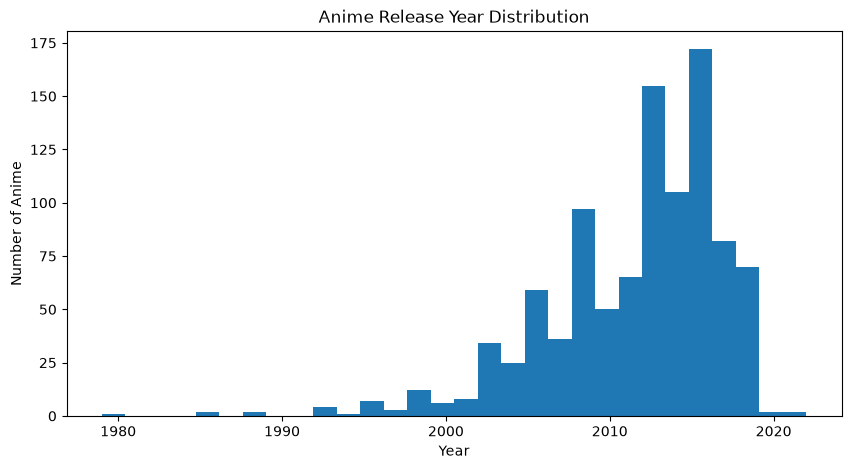

In [17]:
plt.figure(figsize=(10,5))

plt.hist(df['year_of_release'], bins=30)

plt.xlabel("Year")
plt.ylabel("Number of Anime")
plt.title("Anime Release Year Distribution")

plt.show()

In [18]:
year_info=df[['year_of_release']]

In [19]:
year_info.describe()

,year_of_release
count,1000.000000
mean,2011.469000
std,5.381264
min,1979.000000
25%,2008.000000
50%,2013.000000
75%,2015.000000
max,2022.000000


#### Most  of the anime has been released between 2010-2020, 1979 was the year when first anime was released and 50% of the anime is released after 2015

## Genre Analysis -> most important

In [20]:
genre_df = df.assign(
    genre=df['genres'].str.split('|')
).explode('genre')

In [21]:
genre_counts = genre_df['genre'].value_counts()

genre_counts.head(20)

genre
Comedy           507
Action           424
Romance          346
School           310
Drama            273
Supernatural     268
Fantasy          265
Shounen          240
Slice of Life    178
Sci-Fi           175
Adventure        157
Ecchi            145
Mystery          137
Seinen           132
Harem            125
Magic            108
Super Power       90
Psychological     76
Shoujo            66
Historical        58
Name: count, dtype: int64

#### Comedy, Action and Romance are the leading anime Genre.

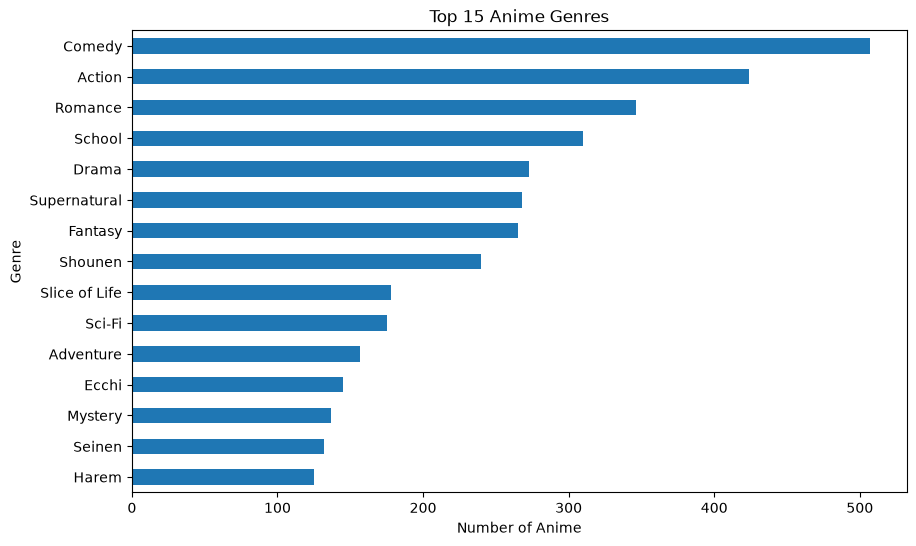

In [22]:
top_genres = genre_counts.head(15)

plt.figure(figsize=(10,6))

top_genres.sort_values().plot(kind='barh')

plt.xlabel("Number of Anime")
plt.ylabel("Genre")
plt.title("Top 15 Anime Genres")

plt.show()

# Multivariate Analysis

## Rating vs Episodes

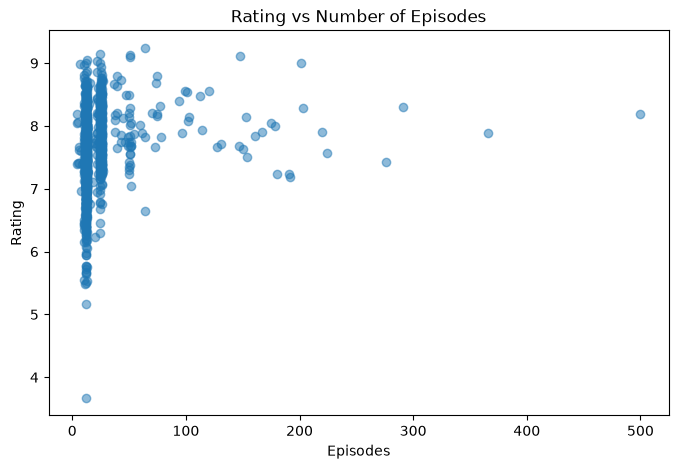

In [23]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['episodes'],
    df['rating'],
    alpha=0.5
)

plt.xlabel("Episodes")
plt.ylabel("Rating")
plt.title("Rating vs Number of Episodes")

plt.show()

In [24]:
df[['episodes', 'rating']].corr()

,episodes,rating
episodes,1.000000,0.169952
rating,0.169952,1.000000


#### 0.17 is the score, So there is a weak positive relationship.Longer anime tend to have slightly higher ratings in this dataset, but the relationship isn't strong.

## Rating vs year of release

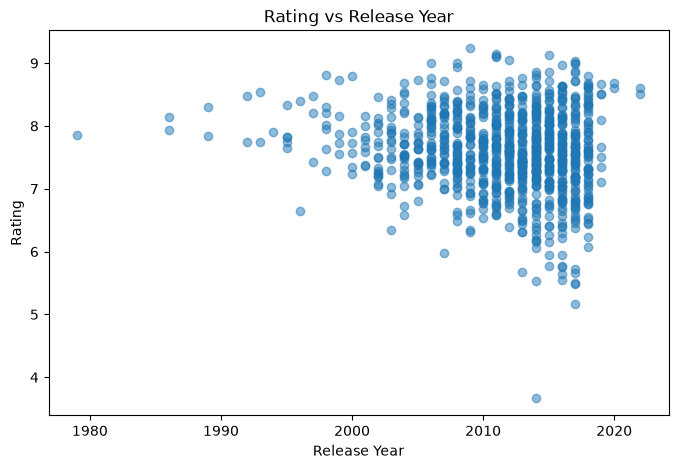

In [25]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['year_of_release'],
    df['rating'],
    alpha=0.5
)

plt.xlabel("Release Year")
plt.ylabel("Rating")
plt.title("Rating vs Release Year")

plt.show()

In [26]:
df[['year_of_release', 'rating']].corr()

,year_of_release,rating
year_of_release,1.000000,-0.134319
rating,-0.134319,1.000000


#### Score is just 0.13 which is too weak to figure out relationship between year of release and rating.

## Episode vs Year

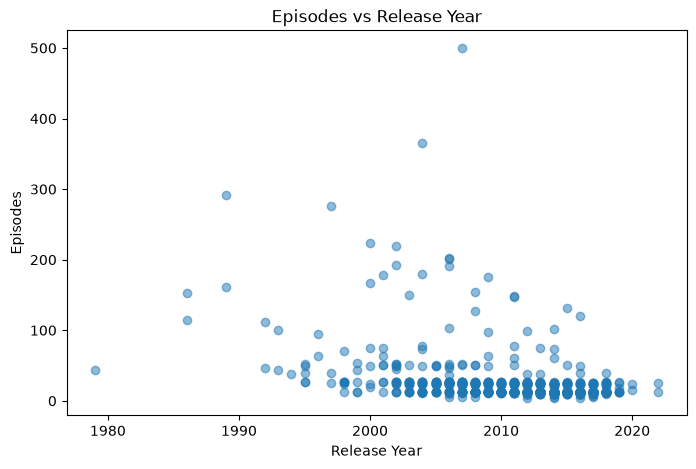

In [27]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['year_of_release'],
    df['episodes'],
    alpha=0.5
)

plt.xlabel("Release Year")
plt.ylabel("Episodes")
plt.title("Episodes vs Release Year")

plt.show()

In [28]:
df[['year_of_release', 'episodes']].corr()

,year_of_release,episodes
year_of_release,1.000000,-0.378579
episodes,-0.378579,1.000000


#### Score is -0.37 which is somewhat high, this means newer the anime fewer its episode

## Correlation Heatmap

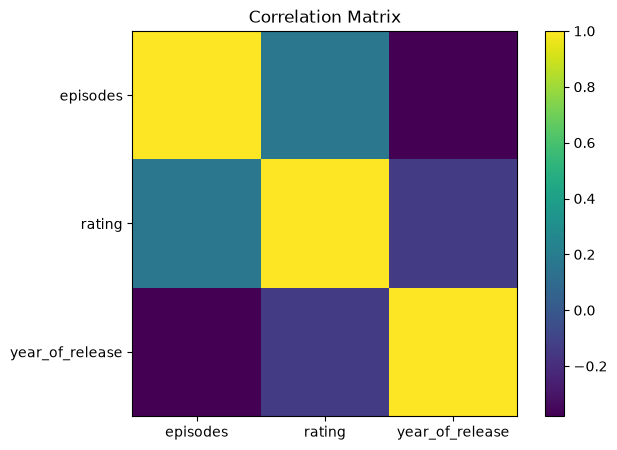

In [29]:
corr = df[
    ['episodes', 'rating', 'year_of_release']
].corr()

plt.figure(figsize=(7,5))

plt.imshow(corr)

plt.xticks(range(len(corr.columns)), corr.columns)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.colorbar()

plt.title("Correlation Matrix")

plt.show()

In [30]:
bins = [0, 12, 24, 50, 100, 200, 1000]

labels = [
    '1-12',
    '13-24',
    '25-50',
    '51-100',
    '101-200',
    '201+'
]

df['episode_group'] = pd.cut(
    df['episodes'],
    bins=bins,
    labels=labels
)

df.groupby(
        'episode_group',
        observed=True
    )['rating'].agg(['count'])


,count
episode_group,
1-12,487
13-24,294
25-50,160
51-100,31
101-200,20
201+,8


#### Around half of the anime has episodes between 1 to 12 and only 8 anime has more than 200 episodes.

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, '1-12'),
  Text(1, 0, '13-24'),
  Text(2, 0, '25-50'),
  Text(3, 0, '51-100'),
  Text(4, 0, '101-200'),
  Text(5, 0, '201+')])

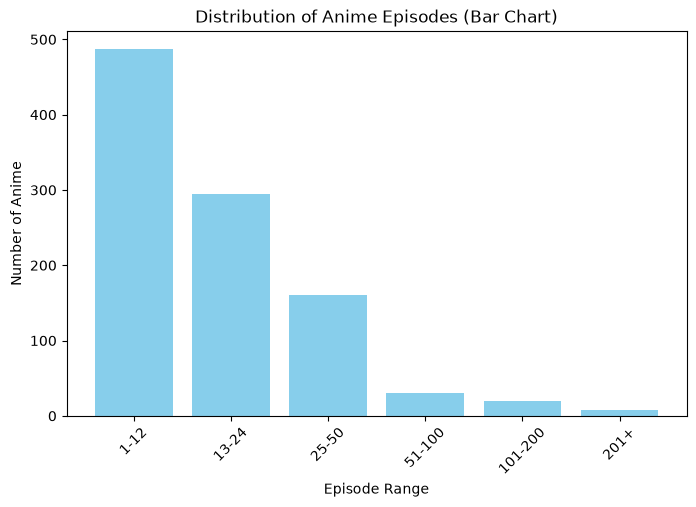

In [31]:
counts = df.groupby('episode_group', observed=True)['rating'].count()

plt.figure(figsize=(8,5))
plt.bar(counts.index.astype(str), counts.values, color='skyblue')

plt.xlabel("Episode Range")
plt.ylabel("Number of Anime")
plt.title("Distribution of Anime Episodes (Bar Chart)")
plt.xticks(rotation=45)

## Genre vs Rating

In [32]:
genre_rating = (
    genre_df
    .groupby('genre')['rating']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)

print(
    genre_rating[
        genre_rating['count'] >= 20
    ].head(15)
)

               count      mean
genre                         
Thriller          25  8.088800
Sports            40  8.006000
Historical        58  7.932414
Josei             20  7.921000
Space             20  7.891000
Music             27  7.850741
Parody            35  7.824000
Shounen          240  7.819542
Slice of Life    178  7.798876
Adventure        157  7.795796
Game              33  7.783636
Drama            273  7.780110
Shoujo            66  7.741061
Military          50  7.739000
Demons            50  7.714200


# Data Cleaning

In [33]:
import numpy as np


df.isnull().sum()

df = df.drop_duplicates()


df = df.drop_duplicates(subset="anime_title")


df["genres"] = df["genres"].fillna("Unknown")
df["anime_title"] = df["anime_title"].str.strip()

df.shape

(1000, 8)

#### Droping duplicates and filling empty values

In [34]:
df = pd.read_csv("anime_dataset_1.csv")


df = df.drop(columns=["anime_id", "type"])

df = df[
    ["anime_title", "genres", "rating", "episodes", "year_of_release"]
]


#### droping anime_id and type cols because it is irrelevant for ML.

In [47]:
df.head(10) #The new dimension of cols

,anime_title,genres,rating,episodes,year_of_release,genres_clean
0,.hack//Sign,Adventure|Fantasy|Game|Magic|Mystery|Sci-Fi,7.08,26,2002,Adventure Fantasy Game Magic Mystery Sci-Fi
1,07-Ghost,Action|Demons|Fantasy|Josei|Magic|Military,7.34,25,2009,Action Demons Fantasy Josei Magic Military
2,11eyes,Action|Ecchi|Super Power|Supernatural,6.35,12,2009,Action Ecchi Super Power Supernatural
3,3D Kanojo: Real Girl,Romance|School|Shoujo,6.75,12,2018,Romance School Shoujo
4,91 Days,Action|Drama|Historical,7.88,12,2016,Action Drama Historical
5,[C] CONTROL - The Money and Soul of Possibility,Action|Mystery|Super Power|Thriller,7.36,11,2011,Action Mystery Super Power Thriller
6,A Bridge to the Starry Skies,Comedy|Ecchi|Harem|Romance|School,6.94,12,2011,Comedy Ecchi Harem Romance School
7,A Certain Magical Index,Action|Magic|Sci-Fi|Super Power,7.60,24,2008,Action Magic Sci-Fi Super Power
8,A Certain Magical Index II,Action|Magic|Sci-Fi|Super Power,7.77,24,2010,Action Magic Sci-Fi Super Power
9,A Certain Magical Index III,Action|Magic|Sci-Fi|Super Power,7.32,26,2018,Action Magic Sci-Fi Super Power


In [36]:
df.shape

(1000, 5)

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   anime_title      1000 non-null   str    
 1   genres           1000 non-null   str    
 2   rating           1000 non-null   float64
 3   episodes         1000 non-null   int64  
 4   year_of_release  1000 non-null   int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 94.1 KB


In [48]:
df["genres_clean"] = df["genres"].str.replace("|", " ", regex=False)

df[["anime_title", "genres", "genres_clean"]].head(15) #Removing | from genres to make it readable

,anime_title,genres,genres_clean
0,.hack//Sign,Adventure|Fantasy|Game|Magic|Mystery|Sci-Fi,Adventure Fantasy Game Magic Mystery Sci-Fi
1,07-Ghost,Action|Demons|Fantasy|Josei|Magic|Military,Action Demons Fantasy Josei Magic Military
2,11eyes,Action|Ecchi|Super Power|Supernatural,Action Ecchi Super Power Supernatural
3,3D Kanojo: Real Girl,Romance|School|Shoujo,Romance School Shoujo
4,91 Days,Action|Drama|Historical,Action Drama Historical
5,[C] CONTROL - The Money and Soul of Possibility,Action|Mystery|Super Power|Thriller,Action Mystery Super Power Thriller
6,A Bridge to the Starry Skies,Comedy|Ecchi|Harem|Romance|School,Comedy Ecchi Harem Romance School
7,A Certain Magical Index,Action|Magic|Sci-Fi|Super Power,Action Magic Sci-Fi Super Power
8,A Certain Magical Index II,Action|Magic|Sci-Fi|Super Power,Action Magic Sci-Fi Super Power
9,A Certain Magical Index III,Action|Magic|Sci-Fi|Super Power,Action Magic Sci-Fi Super Power


# ML part starts from here

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer


df["genres_clean"] = df["genres"].fillna("").str.replace("|", " ", regex=False)


tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(df["genres_clean"])

tfidf_matrix.shape

(1000, 44)

#### anime genre is getting converted from strings/text to the vectors

In [40]:
print(tfidf_matrix)
print(tfidf_matrix.shape)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5273 stored elements and shape (1000, 44)>
  Coords	Values
  (0, 1)	0.3478432041537286
  (0, 10)	0.2841812930320539
  (0, 12)	0.5355939916610097
  (0, 19)	0.39321514739579944
  (0, 24)	0.364383937033848
  (0, 33)	0.33465756259311974
  (0, 11)	0.33465756259311974
  (1, 10)	0.2694000546458756
  (1, 19)	0.3727626863322981
  (1, 0)	0.21510977090802075
  (1, 7)	0.46075949963899604
  (1, 16)	0.5635607719491047
  (1, 22)	0.46075949963899604
  (2, 0)	0.2919275434119892
  (2, 9)	0.4599273617108373
  (2, 40)	0.5342584115351008
  (2, 28)	0.5342584115351008
  (2, 41)	0.36384204093965217
  (3, 30)	0.447175210899846
  (3, 32)	0.4709584597037696
  (3, 35)	0.7604159782580394
  (4, 0)	0.38385663924136687
  (4, 8)	0.4746097168445842
  (4, 14)	0.7920856627834054
  (5, 24)	0.39471367332590407
  :	:
  (994, 7)	0.5728480020284469
  (994, 41)	0.33332128616604917
  (994, 5)	0.24174318664116604
  (994, 36)	0.34561145601643806
  (995, 10)	0.781448998

In [41]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(tfidf_matrix)

print(similarity_matrix.shape)

(1000, 1000)


#### Cosine similarity is used to compare out similarities between two vector, here vectors are being compared with each other.

In [42]:
indices = pd.Series(
    df.index,
    index=df["anime_title"]
).drop_duplicates()

In [51]:
indices["Attack on Titan"] # here we are converting anime title into indices

np.int64(69)

In [ ]:
def recommend_anime(title, n=10):

   
    if title not in indices:
        return "Anime not found"

    
    idx = indices[title]
    similarity_scores = list(enumerate(similarity_matrix[idx]))

    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )


    similarity_scores = similarity_scores[1:n+1]


    anime_indices = [i[0] for i in similarity_scores]


    return df.iloc[anime_indices][
        ["anime_title", "genres_clean", "rating"]
    ]

#### anime title are getting picked, we are finding its similarity score then sorting them picking up top 10 anime related to it.

In [45]:
recommend_anime("Dragon Ball", 10)

,anime_title,genres,rating
213,Dragon Ball Super,Action|Adventure|Comedy|Fantasy|Martial Arts|S...,7.71
214,Dragon Ball Z,Action|Adventure|Comedy|Fantasy|Martial Arts|S...,8.30
215,Dragon Ball Z Kai,Action|Adventure|Comedy|Fantasy|Martial Arts|S...,7.89
216,Dragon Ball Z Kai: The Final Chapters,Action|Adventure|Comedy|Fantasy|Martial Arts|S...,7.89
593,Naruto,Action|Adventure|Comedy|Martial Arts|Shounen|S...,7.90
594,Naruto: Shippuden,Action|Adventure|Comedy|Martial Arts|Shounen|S...,8.19
540,Medaka Box,Action|Comedy|Ecchi|Martial Arts|School|Shoune...,7.16
541,Medaka Box Abnormal,Action|Comedy|Ecchi|Martial Arts|School|Shoune...,7.55
828,Tenjho Tenge,Action|Comedy|Ecchi|Martial Arts|School|Shoune...,7.04
477,Kurokami The Animation,Action|Martial Arts|Seinen|Super Power,7.23


In [46]:
import pickle

model_data = {
    "df": df,
    "tfidf": tfidf,
    "tfidf_matrix": tfidf_matrix,
    "similarity_matrix": similarity_matrix,
    "indices": indices
}

with open("anime_recommender.pkl", "wb") as file:
    pickle.dump(model_data, file)

print("anime_recommender.pkl saved successfully!")

anime_recommender.pkl saved successfully!
